In [1]:
%%capture
!pip uninstall -y numpy pandas scipy scikit-image
!pip install -q numpy==1.26.4 pandas==2.2.2 scipy==1.13.1 scikit-image==0.24.0
!pip install -q ultralytics simple-lama-inpainting lpips opencv-python-headless Pillow matplotlib tqdm


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, shutil, zipfile, random, math, time
from pathlib import Path

PROJECT_NAME = "cse498r_instance_removal_week_update"
BASE_DIR     = Path("/content") / PROJECT_NAME
DATA_DIR     = BASE_DIR / "data"
WORK_DIR     = BASE_DIR / "work"
OUT_DIR      = BASE_DIR / "outputs"
PLOT_DIR     = OUT_DIR / "plots"
VIS_DIR      = OUT_DIR / "selected_visuals"
TMP_DIR      = BASE_DIR / "tmp"

for d in [DATA_DIR, WORK_DIR, OUT_DIR, PLOT_DIR, VIS_DIR, TMP_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DRIVE_ROOT = Path("/content/drive/MyDrive") / PROJECT_NAME
DRIVE_OUT  = DRIVE_ROOT / "outputs"
DRIVE_OUT.mkdir(parents=True, exist_ok=True)

print("BASE_DIR  :", BASE_DIR)
print("DRIVE_OUT :", DRIVE_OUT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE_DIR  : /content/cse498r_instance_removal_week_update
DRIVE_OUT : /content/drive/MyDrive/cse498r_instance_removal_week_update/outputs


In [3]:
from google.colab import files
import os

print("Please upload your dataset zip file (example: coco_200_persons.zip)")
uploaded = files.upload()

ZIP_PATH = list(uploaded.keys())[0]
assert os.path.exists(ZIP_PATH), f"Dataset zip not found: {ZIP_PATH}"

print("Using uploaded zip:", ZIP_PATH)


Please upload your dataset zip file (example: coco_200_persons.zip)


Saving coco_200_persons.zip to coco_200_persons (2).zip
Using uploaded zip: coco_200_persons (2).zip


In [4]:
import zipfile, json
from pathlib import Path

EXTRACT_ROOT = DATA_DIR / "dataset_extracted"
EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)

# Extract only once in current session
if len(list(EXTRACT_ROOT.rglob("*"))) == 0:
    print("Extracting dataset zip...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_ROOT)
else:
    print("Dataset already extracted in this session.")

# Find all images recursively
all_images = sorted(list(EXTRACT_ROOT.rglob("*.jpg"))) + sorted(list(EXTRACT_ROOT.rglob("*.png"))) + sorted(list(EXTRACT_ROOT.rglob("*.jpeg")))
print("Total images found:", len(all_images))

assert len(all_images) > 0, "No images found after extraction. Check zip structure."

# Try to find metadata.json anywhere inside extracted folder
metadata_files = list(EXTRACT_ROOT.rglob("metadata.json"))
if len(metadata_files) > 0:
    metadata_path = metadata_files[0]
    with open(metadata_path, "r") as f:
        metadata = json.load(f)
    print("Metadata loaded from:", metadata_path)
    print("Metadata entries:", len(metadata))
else:
    metadata = []
    print("No metadata.json found. Continuing without metadata.")


Dataset already extracted in this session.
Total images found: 200
Metadata loaded from: /content/cse498r_instance_removal_week_update/data/dataset_extracted/metadata.json
Metadata entries: 200


In [5]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from tqdm.auto import tqdm

from ultralytics import YOLO
from simple_lama_inpainting import SimpleLama
import lpips

from skimage.metrics import peak_signal_noise_ratio as psnr_fn
from skimage.metrics import structural_similarity as ssim_fn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))


DEVICE: cuda
GPU: Tesla T4
VRAM(GB): 14.56


In [6]:
%%time
print("Loading YOLOv8x-seg...")
yolo_seg = YOLO("yolov8x-seg.pt")

print("Loading SimpleLaMa...")
lama = SimpleLama()

print("Loading LPIPS...")
lpips_fn = lpips.LPIPS(net='alex').to(DEVICE).eval()

print("All models loaded.")


Loading YOLOv8x-seg...
Loading SimpleLaMa...
Loading LPIPS...
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/alex.pth
All models loaded.
CPU times: user 1.14 s, sys: 744 ms, total: 1.88 s
Wall time: 1.91 s


In [7]:
# =========================
# DATA / EXPERIMENT CONTROL
# =========================
MAX_IMAGES                 = None
MAX_PERSONS                = 8
YOLO_CONF                  = 0.35
MIN_MASK_AREA              = 1200

SAVE_ONLY_SELECTED_VISUALS = True
NUM_VISUAL_SAMPLES_BEST    = 12
NUM_VISUAL_SAMPLES_WORST   = 8
NUM_VISUAL_SAMPLES_RANDOM  = 8

# =========================
# TUNING CONTROL
# =========================
USE_TUNING_SEARCH          = True
TUNE_IMAGES                = 30
TOPK_CONFIGS_TO_KEEP       = 3

# =========================
# ADAPTIVE MASK PARAMETERS
# =========================
CONFIG_GRID = [
    {
        "name": "cfg_hybrid_small",
        "dilate_frac": 0.040,
        "dilate_min": 9,
        "dilate_max": 35,
        "blur_frac": 0.020,
        "blur_min": 5,
        "blur_max": 21,
        "crop_pad_frac": 0.20,
        "crop_pad_min": 28,
        "crop_pad_max": 180,
        "residual_box_pad_frac": 0.16,
        "residual_box_pad_min": 24,
        "residual_box_pad_max": 140,
        "residual_conf": 0.20,
        "max_refine_passes": 2
    },
    {
        "name": "cfg_hybrid_mid",
        "dilate_frac": 0.055,
        "dilate_min": 11,
        "dilate_max": 45,
        "blur_frac": 0.025,
        "blur_min": 7,
        "blur_max": 25,
        "crop_pad_frac": 0.24,
        "crop_pad_min": 36,
        "crop_pad_max": 220,
        "residual_box_pad_frac": 0.20,
        "residual_box_pad_min": 28,
        "residual_box_pad_max": 180,
        "residual_conf": 0.20,
        "max_refine_passes": 2
    },
    {
        "name": "cfg_hybrid_big",
        "dilate_frac": 0.070,
        "dilate_min": 13,
        "dilate_max": 55,
        "blur_frac": 0.030,
        "blur_min": 9,
        "blur_max": 31,
        "crop_pad_frac": 0.30,
        "crop_pad_min": 44,
        "crop_pad_max": 260,
        "residual_box_pad_frac": 0.24,
        "residual_box_pad_min": 32,
        "residual_box_pad_max": 220,
        "residual_conf": 0.18,
        "max_refine_passes": 3
    }
]

# =========================
# FILES
# =========================
RESULTS_CSV  = OUT_DIR / "metrics_ABCD.csv"
SUMMARY_JSON = OUT_DIR / "summary_ABCD.json"
TUNE_CSV     = OUT_DIR / "tuning_results_ABCD.csv"

print("Configs:", len(CONFIG_GRID))
print("Results CSV:", RESULTS_CSV)


Configs: 3
Results CSV: /content/cse498r_instance_removal_week_update/outputs/metrics_ABCD.csv


In [8]:
def ensure_odd(x: int) -> int:
    x = int(max(1, x))
    return x if x % 2 == 1 else x + 1

def clamp(v, lo, hi):
    return max(lo, min(hi, v))

def read_rgb(path):
    bgr = cv2.imread(str(path))
    if bgr is None:
        raise ValueError(f"Failed to read image: {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)

def to_lpips_tensor(img_rgb):
    arr = img_rgb.astype(np.float32) / 127.5 - 1.0
    ten = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
    return ten

def bbox_from_mask(mask):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0 or len(ys) == 0:
        return None
    return [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]

def expand_box(x1, y1, x2, y2, H, W, pad):
    x1 = max(0, x1 - pad)
    y1 = max(0, y1 - pad)
    x2 = min(W - 1, x2 + pad)
    y2 = min(H - 1, y2 + pad)
    return x1, y1, x2, y2

def crop_with_box(img, box):
    x1, y1, x2, y2 = box
    return img[y1:y2+1, x1:x2+1]

def paste_with_soft_mask(base_rgb, patch_rgb, full_mask):
    alpha = (full_mask.astype(np.float32) / 255.0)[..., None]
    out = patch_rgb.astype(np.float32) * alpha + base_rgb.astype(np.float32) * (1 - alpha)
    return np.clip(out, 0, 255).astype(np.uint8)

def composite_score(mean_psnr, mean_ssim, mean_lpips):
    # higher is better
    return mean_psnr + 15.0 * mean_ssim - 10.0 * mean_lpips


In [9]:
def detect_and_segment(image_rgb, yolo_conf=YOLO_CONF, min_mask_area=MIN_MASK_AREA, max_persons=MAX_PERSONS):
    H, W = image_rgb.shape[:2]
    results = yolo_seg(image_rgb, conf=yolo_conf, classes=[0], verbose=False)[0]

    persons = []
    if results.masks is None or results.boxes is None:
        return persons

    masks_data = results.masks.data.cpu().numpy()
    boxes_data = results.boxes.xyxy.cpu().numpy()
    confs_data = results.boxes.conf.cpu().numpy() if results.boxes.conf is not None else np.ones(len(boxes_data))

    for i in range(len(boxes_data)):
        mask_small = masks_data[i]
        mask_full = cv2.resize(mask_small, (W, H), interpolation=cv2.INTER_LINEAR)
        binary = (mask_full > 0.5).astype(np.uint8) * 255
        area = int(binary.sum() / 255)

        if area < min_mask_area:
            continue

        x1, y1, x2, y2 = map(int, boxes_data[i])
        conf = float(confs_data[i])

        persons.append({
            "bbox": [x1, y1, x2, y2],
            "mask": binary,
            "area": area,
            "conf": conf,
            "cx": (x1 + x2) / 2.0,
            "cy": (y1 + y2) / 2.0,
        })

    persons.sort(key=lambda p: p["area"], reverse=True)
    return persons[:max_persons]


In [10]:
def adaptive_mask_params(person, image_shape, cfg):
    H, W = image_shape[:2]
    x1, y1, x2, y2 = person["bbox"]
    bw = max(1, x2 - x1 + 1)
    bh = max(1, y2 - y1 + 1)
    ref = max(bw, bh)

    dilate_k = ensure_odd(clamp(int(ref * cfg["dilate_frac"]), cfg["dilate_min"], cfg["dilate_max"]))
    blur_k   = ensure_odd(clamp(int(ref * cfg["blur_frac"]),   cfg["blur_min"],   cfg["blur_max"]))
    crop_pad = int(clamp(ref * cfg["crop_pad_frac"], cfg["crop_pad_min"], cfg["crop_pad_max"]))

    return dilate_k, blur_k, crop_pad

def refine_person_mask(mask, dilate_k, blur_k):
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (dilate_k, dilate_k))
    dilated = cv2.dilate(mask, kernel, iterations=1)

    feather = cv2.GaussianBlur(dilated.astype(np.float32), (blur_k, blur_k), 0)
    out = (feather > 127).astype(np.uint8) * 255
    return out

def sort_persons(persons, image_shape, strategy="largest_first"):
    if strategy == "largest_first":
        return sorted(persons, key=lambda p: p["area"], reverse=True)

    elif strategy == "center_first":
        H, W = image_shape[:2]
        cx0, cy0 = W / 2.0, H / 2.0
        return sorted(
            persons,
            key=lambda p: ((p["cx"] - cx0) ** 2 + (p["cy"] - cy0) ** 2)
        )

    elif strategy == "confidence_first":
        return sorted(persons, key=lambda p: p["conf"], reverse=True)

    return persons


In [11]:
def lama_inpaint_rgb(image_rgb, mask):
    """
    Inpaint image_rgb using SimpleLaMa.
    Always force the returned image to match the input spatial size.
    """
    pil_img = Image.fromarray(image_rgb)
    pil_mask = Image.fromarray(mask)
    result = lama(pil_img, pil_mask)
    out = np.array(result.convert("RGB"))

    # Safety resize in case model output size changes slightly
    if out.shape[:2] != image_rgb.shape[:2]:
        out = cv2.resize(out, (image_rgb.shape[1], image_rgb.shape[0]), interpolation=cv2.INTER_LINEAR)

    return out


def local_crop_inpaint(image_rgb, person, cfg):
    H, W = image_rgb.shape[:2]
    dilate_k, blur_k, crop_pad = adaptive_mask_params(person, image_rgb.shape, cfg)

    refined_mask = refine_person_mask(person["mask"], dilate_k, blur_k)
    box = bbox_from_mask(refined_mask)
    if box is None:
        return image_rgb.copy(), np.zeros((H, W), dtype=np.uint8), None

    x1, y1, x2, y2 = box
    x1, y1, x2, y2 = expand_box(x1, y1, x2, y2, H, W, crop_pad)

    crop_img = image_rgb[y1:y2+1, x1:x2+1].copy()
    crop_mask = refined_mask[y1:y2+1, x1:x2+1].copy()

    # Inpaint crop
    inpainted_crop = lama_inpaint_rgb(crop_img, crop_mask)

    # Extra safety: make sure result exactly matches crop size
    ch, cw = crop_img.shape[:2]
    if inpainted_crop.shape[:2] != (ch, cw):
        inpainted_crop = cv2.resize(inpainted_crop, (cw, ch), interpolation=cv2.INTER_LINEAR)

    # Soft blending mask
    blur_for_blend = ensure_odd(max(5, blur_k))
    crop_mask_soft = cv2.GaussianBlur(
        crop_mask.astype(np.float32),
        (blur_for_blend, blur_for_blend),
        0
    )
    crop_mask_soft = np.clip(crop_mask_soft, 0, 255).astype(np.uint8)

    # Safety: ensure soft mask size matches crop
    if crop_mask_soft.shape[:2] != (ch, cw):
        crop_mask_soft = cv2.resize(crop_mask_soft, (cw, ch), interpolation=cv2.INTER_LINEAR)

    orig_crop = image_rgb[y1:y2+1, x1:x2+1]

    alpha = (crop_mask_soft.astype(np.float32) / 255.0)[..., None]

    mixed_crop = np.clip(
        inpainted_crop.astype(np.float32) * alpha +
        orig_crop.astype(np.float32) * (1 - alpha),
        0, 255
    ).astype(np.uint8)

    out = image_rgb.copy()
    out[y1:y2+1, x1:x2+1] = mixed_crop

    full_mask = np.zeros((H, W), dtype=np.uint8)
    full_mask[y1:y2+1, x1:x2+1] = crop_mask

    info = {
        "dilate_k": dilate_k,
        "blur_k": blur_k,
        "crop_pad": crop_pad,
        "crop_box": [x1, y1, x2, y2]
    }
    return out, full_mask, info


In [12]:
def build_union_mask(image_rgb, persons, cfg):
    H, W = image_rgb.shape[:2]
    union_mask = np.zeros((H, W), dtype=np.uint8)

    for p in persons:
        dilate_k, blur_k, _ = adaptive_mask_params(p, image_rgb.shape, cfg)
        m = refine_person_mask(p["mask"], dilate_k, blur_k)
        union_mask = np.maximum(union_mask, m)

    return union_mask


def method_A_single_shot_global(image_rgb, persons, cfg):
    union_mask = build_union_mask(image_rgb, persons, cfg)

    t0 = time.time()
    result = lama_inpaint_rgb(image_rgb, union_mask)

    return {
        "result": result,
        "union_mask": union_mask,
        "time_s": round(time.time() - t0, 3)
    }


def method_B_progressive_global(image_rgb, persons, cfg, sort_strategy="largest_first"):
    H, W = image_rgb.shape[:2]
    current = image_rgb.copy()
    union_mask = np.zeros((H, W), dtype=np.uint8)

    ordered = sort_persons(persons, image_rgb.shape, strategy=sort_strategy)

    t0 = time.time()
    for p in ordered:
        dilate_k, blur_k, _ = adaptive_mask_params(p, image_rgb.shape, cfg)
        m = refine_person_mask(p["mask"], dilate_k, blur_k)
        union_mask = np.maximum(union_mask, m)
        current = lama_inpaint_rgb(current, m)

    return {
        "result": current,
        "union_mask": union_mask,
        "time_s": round(time.time() - t0, 3)
    }


def method_C_progressive_local(image_rgb, persons, cfg, sort_strategy="largest_first"):
    H, W = image_rgb.shape[:2]
    current = image_rgb.copy()
    union_mask = np.zeros((H, W), dtype=np.uint8)

    ordered = sort_persons(persons, image_rgb.shape, strategy=sort_strategy)

    t0 = time.time()
    for p in ordered:
        current, local_mask, _ = local_crop_inpaint(current, p, cfg)
        union_mask = np.maximum(union_mask, local_mask)

    return {
        "result": current,
        "union_mask": union_mask,
        "time_s": round(time.time() - t0, 3)
    }


def detect_residual_boxes(image_rgb, conf=0.20):
    results = yolo_seg(image_rgb, conf=conf, classes=[0], verbose=False)[0]
    residuals = []

    if results.boxes is None or len(results.boxes) == 0:
        return residuals

    xyxy = results.boxes.xyxy.cpu().numpy()
    confs = results.boxes.conf.cpu().numpy() if results.boxes.conf is not None else np.ones(len(xyxy))

    for box, c in zip(xyxy, confs):
        x1, y1, x2, y2 = map(int, box)
        residuals.append({
            "bbox": [x1, y1, x2, y2],
            "conf": float(c)
        })

    return residuals


def residual_box_mask(image_shape, bbox, cfg):
    H, W = image_shape[:2]
    x1, y1, x2, y2 = bbox
    bw = max(1, x2 - x1 + 1)
    bh = max(1, y2 - y1 + 1)
    ref = max(bw, bh)

    pad = int(clamp(
        ref * cfg["residual_box_pad_frac"],
        cfg["residual_box_pad_min"],
        cfg["residual_box_pad_max"]
    ))

    x1, y1, x2, y2 = expand_box(x1, y1, x2, y2, H, W, pad)

    mask = np.zeros((H, W), dtype=np.uint8)
    mask[y1:y2+1, x1:x2+1] = 255

    k = ensure_odd(clamp(int(ref * 0.08), 9, 41))
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    mask = cv2.dilate(mask, kernel, iterations=1)

    blur_k = ensure_odd(clamp(int(ref * 0.04), 7, 31))
    mask = cv2.GaussianBlur(mask.astype(np.float32), (blur_k, blur_k), 0)
    mask = np.clip(mask, 0, 255).astype(np.uint8)
    mask = (mask > 80).astype(np.uint8) * 255
    return mask


def method_D_hybrid_global_then_refine(image_rgb, persons, cfg):
    """
    Stage 1: global union-mask inpainting (A-like)
    Stage 2: detect residual persons and refine only remaining regions
    """
    H, W = image_rgb.shape[:2]
    t0 = time.time()

    union_mask = build_union_mask(image_rgb, persons, cfg)
    current = lama_inpaint_rgb(image_rgb, union_mask)

    refined_union = union_mask.copy()

    for _ in range(cfg["max_refine_passes"]):
        residuals = detect_residual_boxes(current, conf=cfg["residual_conf"])
        if len(residuals) == 0:
            break

        any_change = False
        for r in residuals:
            rm = residual_box_mask(current.shape, r["bbox"], cfg)
            current = lama_inpaint_rgb(current, rm)
            refined_union = np.maximum(refined_union, rm)
            any_change = True

        if not any_change:
            break

    return {
        "result": current,
        "union_mask": refined_union,
        "time_s": round(time.time() - t0, 3)
    }


In [13]:
def crop_bbox_from_binary(binary_mask):
    ys, xs = np.where(binary_mask > 0)
    if len(xs) == 0 or len(ys) == 0:
        return None
    return ys.min(), ys.max(), xs.min(), xs.max()


def compute_metrics_inside(original, reconstructed, mask):
    m = mask > 127
    if not m.any():
        return {"PSNR": 0.0, "SSIM": 0.0, "LPIPS": 1.0, "mask_coverage_%": 0.0}

    box = crop_bbox_from_binary(m.astype(np.uint8))
    if box is None:
        return {"PSNR": 0.0, "SSIM": 0.0, "LPIPS": 1.0, "mask_coverage_%": 0.0}

    y1, y2, x1, x2 = box
    orig_c = original[y1:y2+1, x1:x2+1]
    recon_c = reconstructed[y1:y2+1, x1:x2+1]

    if orig_c.shape[0] < 8 or orig_c.shape[1] < 8:
        return {
            "PSNR": 0.0,
            "SSIM": 0.0,
            "LPIPS": 1.0,
            "mask_coverage_%": round(float(100.0 * m.sum() / m.size), 3)
        }

    psnr_val = psnr_fn(orig_c, recon_c, data_range=255)
    ssim_val = ssim_fn(orig_c, recon_c, channel_axis=2, data_range=255)

    with torch.no_grad():
        lp = lpips_fn(to_lpips_tensor(orig_c), to_lpips_tensor(recon_c)).item()

    return {
        "PSNR": round(float(psnr_val), 4),
        "SSIM": round(float(ssim_val), 4),
        "LPIPS": round(float(lp), 4),
        "mask_coverage_%": round(float(100.0 * m.sum() / m.size), 3)
    }


def compute_metrics_outside(original, reconstructed, mask):
    outside = (mask <= 127).astype(np.uint8)
    box = crop_bbox_from_binary(outside)
    if box is None:
        return {"OUT_PSNR": 0.0, "OUT_SSIM": 0.0, "OUT_LPIPS": 1.0}

    y1, y2, x1, x2 = box
    orig_c = original[y1:y2+1, x1:x2+1]
    recon_c = reconstructed[y1:y2+1, x1:x2+1]

    if orig_c.shape[0] < 8 or orig_c.shape[1] < 8:
        return {"OUT_PSNR": 0.0, "OUT_SSIM": 0.0, "OUT_LPIPS": 1.0}

    psnr_val = psnr_fn(orig_c, recon_c, data_range=255)
    ssim_val = ssim_fn(orig_c, recon_c, channel_axis=2, data_range=255)

    with torch.no_grad():
        lp = lpips_fn(to_lpips_tensor(orig_c), to_lpips_tensor(recon_c)).item()

    return {
        "OUT_PSNR": round(float(psnr_val), 4),
        "OUT_SSIM": round(float(ssim_val), 4),
        "OUT_LPIPS": round(float(lp), 4),
    }


def residual_person_score(image_rgb, conf=0.25):
    results = yolo_seg(image_rgb, conf=conf, classes=[0], verbose=False)[0]

    if results.boxes is None or len(results.boxes) == 0:
        return {
            "remaining_persons": 0,
            "remaining_conf_sum": 0.0,
            "remaining_max_conf": 0.0
        }

    confs = results.boxes.conf.cpu().numpy() if results.boxes.conf is not None else np.ones(len(results.boxes))
    return {
        "remaining_persons": int(len(confs)),
        "remaining_conf_sum": round(float(confs.sum()), 4),
        "remaining_max_conf": round(float(confs.max()) if len(confs) > 0 else 0.0, 4)
    }


def compute_all_metrics(original, reconstructed, mask):
    inside = compute_metrics_inside(original, reconstructed, mask)
    outside = compute_metrics_outside(original, reconstructed, mask)
    out = {}
    out.update(inside)
    out.update(outside)
    return out


def overlay_detections(image_rgb, persons):
    vis = image_rgb.copy()
    for i, p in enumerate(persons):
        x1, y1, x2, y2 = p["bbox"]
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 80), 3)
        cv2.putText(vis, f"P{i+1}", (x1+4, y1+28), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 80), 2)
    return vis


def overlay_mask(image_rgb, persons):
    vis = image_rgb.copy().astype(np.float32)
    for p in persons:
        alpha = (p["mask"] / 255.0)[..., None]
        green = np.zeros_like(vis)
        green[..., 1] = 255
        vis = vis * (1 - 0.40 * alpha) + green * (0.40 * alpha)
    return np.clip(vis, 0, 255).astype(np.uint8)


def save_visual_grid(stem, original, persons, outA, outB, outC, outD, mA, mB, mC, mD, save_path):
    det = overlay_detections(original, persons)
    seg = overlay_mask(original, persons)

    rA = residual_person_score(outA["result"])
    rB = residual_person_score(outB["result"])
    rC = residual_person_score(outC["result"])
    rD = residual_person_score(outD["result"])

    fig, axes = plt.subplots(1, 7, figsize=(42, 6))
    fig.suptitle(f"{stem} | {len(persons)} person(s)", fontsize=14, fontweight="bold")

    def show(ax, img, title):
        ax.imshow(img)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

    show(axes[0], original, "Original")
    show(axes[1], det, "Detection")
    show(axes[2], seg, "Mask")
    show(axes[3], outA["result"], f"A\nPSNR={mA['PSNR']} SSIM={mA['SSIM']} LPIPS={mA['LPIPS']}\nRemain={rA['remaining_persons']}")
    show(axes[4], outB["result"], f"B\nPSNR={mB['PSNR']} SSIM={mB['SSIM']} LPIPS={mB['LPIPS']}\nRemain={rB['remaining_persons']}")
    show(axes[5], outC["result"], f"C\nPSNR={mC['PSNR']} SSIM={mC['SSIM']} LPIPS={mC['LPIPS']}\nRemain={rC['remaining_persons']}")
    show(axes[6], outD["result"], f"D\nPSNR={mD['PSNR']} SSIM={mD['SSIM']} LPIPS={mD['LPIPS']}\nRemain={rD['remaining_persons']}")

    plt.tight_layout()
    plt.savefig(save_path, dpi=170, bbox_inches="tight")
    plt.close(fig)


In [14]:
def pick_tuning_subset(image_paths, n=TUNE_IMAGES):
    if n is None or n >= len(image_paths):
        return image_paths
    idxs = np.linspace(0, len(image_paths) - 1, n).astype(int)
    return [image_paths[i] for i in idxs]


def evaluate_one_image_for_tuning(img_path, cfg):
    image_rgb = read_rgb(img_path)
    persons = detect_and_segment(image_rgb)

    if len(persons) == 0:
        return None

    outA = method_A_single_shot_global(image_rgb, persons, cfg)
    outD = method_D_hybrid_global_then_refine(image_rgb, persons, cfg)

    mA = compute_all_metrics(image_rgb, outA["result"], outA["union_mask"])
    mD = compute_all_metrics(image_rgb, outD["result"], outD["union_mask"])

    rA = residual_person_score(outA["result"])
    rD = residual_person_score(outD["result"])

    return {
        "image": Path(img_path).stem,
        "n_persons": len(persons),

        "A_PSNR": mA["PSNR"],
        "A_SSIM": mA["SSIM"],
        "A_LPIPS": mA["LPIPS"],
        "A_OUT_SSIM": mA["OUT_SSIM"],
        "A_remaining_persons": rA["remaining_persons"],
        "A_remaining_conf_sum": rA["remaining_conf_sum"],

        "D_PSNR": mD["PSNR"],
        "D_SSIM": mD["SSIM"],
        "D_LPIPS": mD["LPIPS"],
        "D_OUT_SSIM": mD["OUT_SSIM"],
        "D_remaining_persons": rD["remaining_persons"],
        "D_remaining_conf_sum": rD["remaining_conf_sum"],

        "dPSNR": mD["PSNR"] - mA["PSNR"],
        "dSSIM": mD["SSIM"] - mA["SSIM"],
        "dLPIPS": mD["LPIPS"] - mA["LPIPS"],
        "dOUT_SSIM": mD["OUT_SSIM"] - mA["OUT_SSIM"],
        "dRemainPersons": rD["remaining_persons"] - rA["remaining_persons"],
        "dRemainConf": rD["remaining_conf_sum"] - rA["remaining_conf_sum"],
    }


tune_summary = []
best_cfg = CONFIG_GRID[0]

if USE_TUNING_SEARCH:
    tune_subset = pick_tuning_subset(all_images, TUNE_IMAGES)
    print("Tuning subset size:", len(tune_subset))

    for cfg in CONFIG_GRID:
        rows = []
        print(f"\nTesting config: {cfg['name']}")

        for img_path in tqdm(tune_subset):
            try:
                row = evaluate_one_image_for_tuning(img_path, cfg)
                if row is not None:
                    rows.append(row)
            except Exception as e:
                print("Error on", img_path, "->", e)

        if len(rows) == 0:
            continue

        df_t = pd.DataFrame(rows)

        score = (
            1.5 * df_t["dPSNR"].mean()
            + 20.0 * df_t["dSSIM"].mean()
            - 12.0 * df_t["dLPIPS"].mean()
            + 12.0 * df_t["dOUT_SSIM"].mean()
            - 2.5 * df_t["dRemainPersons"].mean()
            - 1.2 * df_t["dRemainConf"].mean()
        )

        tune_summary.append({
            "config_name": cfg["name"],
            "mean_dPSNR_D_minus_A": round(float(df_t["dPSNR"].mean()), 5),
            "mean_dSSIM_D_minus_A": round(float(df_t["dSSIM"].mean()), 5),
            "mean_dLPIPS_D_minus_A": round(float(df_t["dLPIPS"].mean()), 5),
            "mean_dOUT_SSIM_D_minus_A": round(float(df_t["dOUT_SSIM"].mean()), 5),
            "mean_dRemainPersons_D_minus_A": round(float(df_t["dRemainPersons"].mean()), 5),
            "mean_dRemainConf_D_minus_A": round(float(df_t["dRemainConf"].mean()), 5),
            "score": round(float(score), 5)
        })

    tune_df = pd.DataFrame(tune_summary).sort_values("score", ascending=False)
    display(tune_df)
    tune_df.to_csv(TUNE_CSV, index=False)

    best_name = tune_df.iloc[0]["config_name"]
    best_cfg = [c for c in CONFIG_GRID if c["name"] == best_name][0]
    print("\nBest config selected:", best_cfg["name"])
else:
    print("Tuning disabled. Using first config.")
    best_cfg = CONFIG_GRID[0]

print("Final config for full run:", best_cfg)


Tuning subset size: 30

Testing config: cfg_hybrid_small


  0%|          | 0/30 [00:00<?, ?it/s]


Testing config: cfg_hybrid_mid


  0%|          | 0/30 [00:00<?, ?it/s]


Testing config: cfg_hybrid_big


  0%|          | 0/30 [00:00<?, ?it/s]

,config_name,mean_dPSNR_D_minus_A,mean_dSSIM_D_minus_A,mean_dLPIPS_D_minus_A,mean_dOUT_SSIM_D_minus_A,mean_dRemainPersons_D_minus_A,mean_dRemainConf_D_minus_A,score
0,cfg_hybrid_small,-0.79732,-0.06667,0.11128,-0.08362,-3.43333,-1.63553,5.67793
2,cfg_hybrid_big,-0.49262,-0.05467,0.09308,-0.06706,-2.93333,-1.45116,5.32078
1,cfg_hybrid_mid,-0.73845,-0.06445,0.10145,-0.08198,-3.13333,-1.47800,5.00908



Best config selected: cfg_hybrid_small
Final config for full run: {'name': 'cfg_hybrid_small', 'dilate_frac': 0.04, 'dilate_min': 9, 'dilate_max': 35, 'blur_frac': 0.02, 'blur_min': 5, 'blur_max': 21, 'crop_pad_frac': 0.2, 'crop_pad_min': 28, 'crop_pad_max': 180, 'residual_box_pad_frac': 0.16, 'residual_box_pad_min': 24, 'residual_box_pad_max': 140, 'residual_conf': 0.2, 'max_refine_passes': 2}


In [15]:
rows = []
selected_images = all_images[:MAX_IMAGES] if MAX_IMAGES is not None else all_images

print("Running full evaluation on", len(selected_images), "images")
skipped = 0
failed = 0

for img_path in tqdm(selected_images):
    stem = Path(img_path).stem
    try:
        image_rgb = read_rgb(img_path)
        persons = detect_and_segment(image_rgb)

        if len(persons) == 0:
            skipped += 1
            continue

        outA = method_A_single_shot_global(image_rgb, persons, best_cfg)
        outB = method_B_progressive_global(image_rgb, persons, best_cfg, sort_strategy="largest_first")
        outC = method_C_progressive_local(image_rgb, persons, best_cfg, sort_strategy="largest_first")
        outD = method_D_hybrid_global_then_refine(image_rgb, persons, best_cfg)

        mA = compute_all_metrics(image_rgb, outA["result"], outA["union_mask"])
        mB = compute_all_metrics(image_rgb, outB["result"], outB["union_mask"])
        mC = compute_all_metrics(image_rgb, outC["result"], outC["union_mask"])
        mD = compute_all_metrics(image_rgb, outD["result"], outD["union_mask"])

        rA = residual_person_score(outA["result"])
        rB = residual_person_score(outB["result"])
        rC = residual_person_score(outC["result"])
        rD = residual_person_score(outD["result"])

        rows.append({
            "image": stem,
            "n_persons": len(persons),

            "A_PSNR": mA["PSNR"], "A_SSIM": mA["SSIM"], "A_LPIPS": mA["LPIPS"], "A_OUT_SSIM": mA["OUT_SSIM"],
            "A_time_s": outA["time_s"], "A_mask_cov": mA["mask_coverage_%"],
            "A_remaining_persons": rA["remaining_persons"], "A_remaining_conf_sum": rA["remaining_conf_sum"],

            "B_PSNR": mB["PSNR"], "B_SSIM": mB["SSIM"], "B_LPIPS": mB["LPIPS"], "B_OUT_SSIM": mB["OUT_SSIM"],
            "B_time_s": outB["time_s"], "B_mask_cov": mB["mask_coverage_%"],
            "B_remaining_persons": rB["remaining_persons"], "B_remaining_conf_sum": rB["remaining_conf_sum"],

            "C_PSNR": mC["PSNR"], "C_SSIM": mC["SSIM"], "C_LPIPS": mC["LPIPS"], "C_OUT_SSIM": mC["OUT_SSIM"],
            "C_time_s": outC["time_s"], "C_mask_cov": mC["mask_coverage_%"],
            "C_remaining_persons": rC["remaining_persons"], "C_remaining_conf_sum": rC["remaining_conf_sum"],

            "D_PSNR": mD["PSNR"], "D_SSIM": mD["SSIM"], "D_LPIPS": mD["LPIPS"], "D_OUT_SSIM": mD["OUT_SSIM"],
            "D_time_s": outD["time_s"], "D_mask_cov": mD["mask_coverage_%"],
            "D_remaining_persons": rD["remaining_persons"], "D_remaining_conf_sum": rD["remaining_conf_sum"],

            "dPSNR_D_minus_A": mD["PSNR"] - mA["PSNR"],
            "dSSIM_D_minus_A": mD["SSIM"] - mA["SSIM"],
            "dLPIPS_D_minus_A": mD["LPIPS"] - mA["LPIPS"],
            "dOUT_SSIM_D_minus_A": mD["OUT_SSIM"] - mA["OUT_SSIM"],
            "dRemainPersons_D_minus_A": rD["remaining_persons"] - rA["remaining_persons"],
            "dRemainConf_D_minus_A": rD["remaining_conf_sum"] - rA["remaining_conf_sum"],
        })

    except Exception as e:
        failed += 1
        print("Error on", img_path, "->", e)

df = pd.DataFrame(rows)
df.to_csv(RESULTS_CSV, index=False)

print("Done.")
print("Processed:", len(df))
print("Skipped (no person):", skipped)
print("Failed:", failed)
display(df.head())


Running full evaluation on 200 images


  0%|          | 0/200 [00:00<?, ?it/s]

Done.
Processed: 200
Skipped (no person): 0
Failed: 0


,image,n_persons,A_PSNR,A_SSIM,A_LPIPS,A_OUT_SSIM,A_time_s,A_mask_cov,A_remaining_persons,A_remaining_conf_sum,...,D_time_s,D_mask_cov,D_remaining_persons,D_remaining_conf_sum,dPSNR_D_minus_A,dSSIM_D_minus_A,dLPIPS_D_minus_A,dOUT_SSIM_D_minus_A,dRemainPersons_D_minus_A,dRemainConf_D_minus_A
0,000000001000,8,12.8562,0.4962,0.5323,0.6188,0.168,43.724,3,2.1367,...,0.983,75.184,0,0.0,-0.5650,-0.1595,0.2334,-0.2378,-3,-2.1367
1,000000002685,7,14.3117,0.4299,0.3960,0.4507,0.199,43.755,1,0.4104,...,0.571,49.439,0,0.0,-0.7354,-0.0528,0.0696,-0.0511,-1,-0.4104
2,000000004134,8,12.4207,0.4133,0.4900,0.4733,0.155,60.329,9,3.3492,...,2.448,77.197,0,0.0,-2.1246,-0.0633,0.2510,-0.1051,-9,-3.3492
3,000000005001,8,11.2269,0.4939,0.4237,0.5493,0.167,55.756,13,6.9322,...,2.710,86.658,0,0.0,-1.0521,-0.1996,0.2919,-0.2550,-13,-6.9322
4,000000005193,6,14.0534,0.4222,0.4057,0.5098,0.157,40.732,0,0.0000,...,0.219,40.732,0,0.0,0.0000,0.0000,0.0000,0.0000,0,0.0000


In [16]:
assert RESULTS_CSV.exists(), "Run full evaluation first."
df = pd.read_csv(RESULTS_CSV)

summary_table = pd.DataFrame({
    "Method": ["A Single-shot", "B Progressive-global", "C Progressive-local", "D Hybrid-refine"],
    "PSNR↑": [df["A_PSNR"].mean(), df["B_PSNR"].mean(), df["C_PSNR"].mean(), df["D_PSNR"].mean()],
    "SSIM↑": [df["A_SSIM"].mean(), df["B_SSIM"].mean(), df["C_SSIM"].mean(), df["D_SSIM"].mean()],
    "LPIPS↓": [df["A_LPIPS"].mean(), df["B_LPIPS"].mean(), df["C_LPIPS"].mean(), df["D_LPIPS"].mean()],
    "OUT_SSIM↑": [df["A_OUT_SSIM"].mean(), df["B_OUT_SSIM"].mean(), df["C_OUT_SSIM"].mean(), df["D_OUT_SSIM"].mean()],
    "RemainPersons↓": [df["A_remaining_persons"].mean(), df["B_remaining_persons"].mean(), df["C_remaining_persons"].mean(), df["D_remaining_persons"].mean()],
    "RemainConf↓": [df["A_remaining_conf_sum"].mean(), df["B_remaining_conf_sum"].mean(), df["C_remaining_conf_sum"].mean(), df["D_remaining_conf_sum"].mean()],
    "Time(s)↓": [df["A_time_s"].mean(), df["B_time_s"].mean(), df["C_time_s"].mean(), df["D_time_s"].mean()],
})

summary = {
    "n_images": int(len(df)),
    "best_config": best_cfg,
    "summary_table": summary_table.round(4).to_dict(orient="records")
}

save_json(summary, SUMMARY_JSON)
display(summary_table.round(4))
print(json.dumps(summary, indent=2))


,Method,PSNR↑,SSIM↑,LPIPS↓,OUT_SSIM↑,RemainPersons↓,RemainConf↓,Time(s)↓
0,A Single-shot,13.3552,0.4526,0.4340,0.5455,3.130,1.5637,0.1672
1,B Progressive-global,12.7937,0.3974,0.4919,0.4765,4.385,2.2815,1.0473
2,C Progressive-local,13.9627,0.5830,0.3872,0.6868,4.125,2.1481,0.3823
3,D Hybrid-refine,12.7361,0.3985,0.5462,0.4751,0.010,0.0044,0.9578


{
  "n_images": 200,
  "best_config": {
    "name": "cfg_hybrid_small",
    "dilate_frac": 0.04,
    "dilate_min": 9,
    "dilate_max": 35,
    "blur_frac": 0.02,
    "blur_min": 5,
    "blur_max": 21,
    "crop_pad_frac": 0.2,
    "crop_pad_min": 28,
    "crop_pad_max": 180,
    "residual_box_pad_frac": 0.16,
    "residual_box_pad_min": 24,
    "residual_box_pad_max": 140,
    "residual_conf": 0.2,
    "max_refine_passes": 2
  },
  "summary_table": [
    {
      "Method": "A Single-shot",
      "PSNR\u2191": 13.3552,
      "SSIM\u2191": 0.4526,
      "LPIPS\u2193": 0.434,
      "OUT_SSIM\u2191": 0.5455,
      "RemainPersons\u2193": 3.13,
      "RemainConf\u2193": 1.5637,
      "Time(s)\u2193": 0.1672
    },
    {
      "Method": "B Progressive-global",
      "PSNR\u2191": 12.7937,
      "SSIM\u2191": 0.3974,
      "LPIPS\u2193": 0.4919,
      "OUT_SSIM\u2191": 0.4765,
      "RemainPersons\u2193": 4.385,
      "RemainConf\u2193": 2.2815,
      "Time(s)\u2193": 1.0473
    },
    {
     

/tmp/ipykernel_21282/2300061225.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([df[f"A_{m}"], df[f"B_{m}"], df[f"C_{m}"], df[f"D_{m}"]], labels=["A", "B", "C", "D"], notch=True)
/tmp/ipykernel_21282/2300061225.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([df[f"A_{m}"], df[f"B_{m}"], df[f"C_{m}"], df[f"D_{m}"]], labels=["A", "B", "C", "D"], notch=True)
/tmp/ipykernel_21282/2300061225.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([df[f"A_{m}"], df[f"B_{m}"], df[f"C_{m}"], df[f"D_{m}"]], labels=["A", "B", "C", "D"], notch=True)
/tmp/ipykernel_21282/2300061225.py:16: M

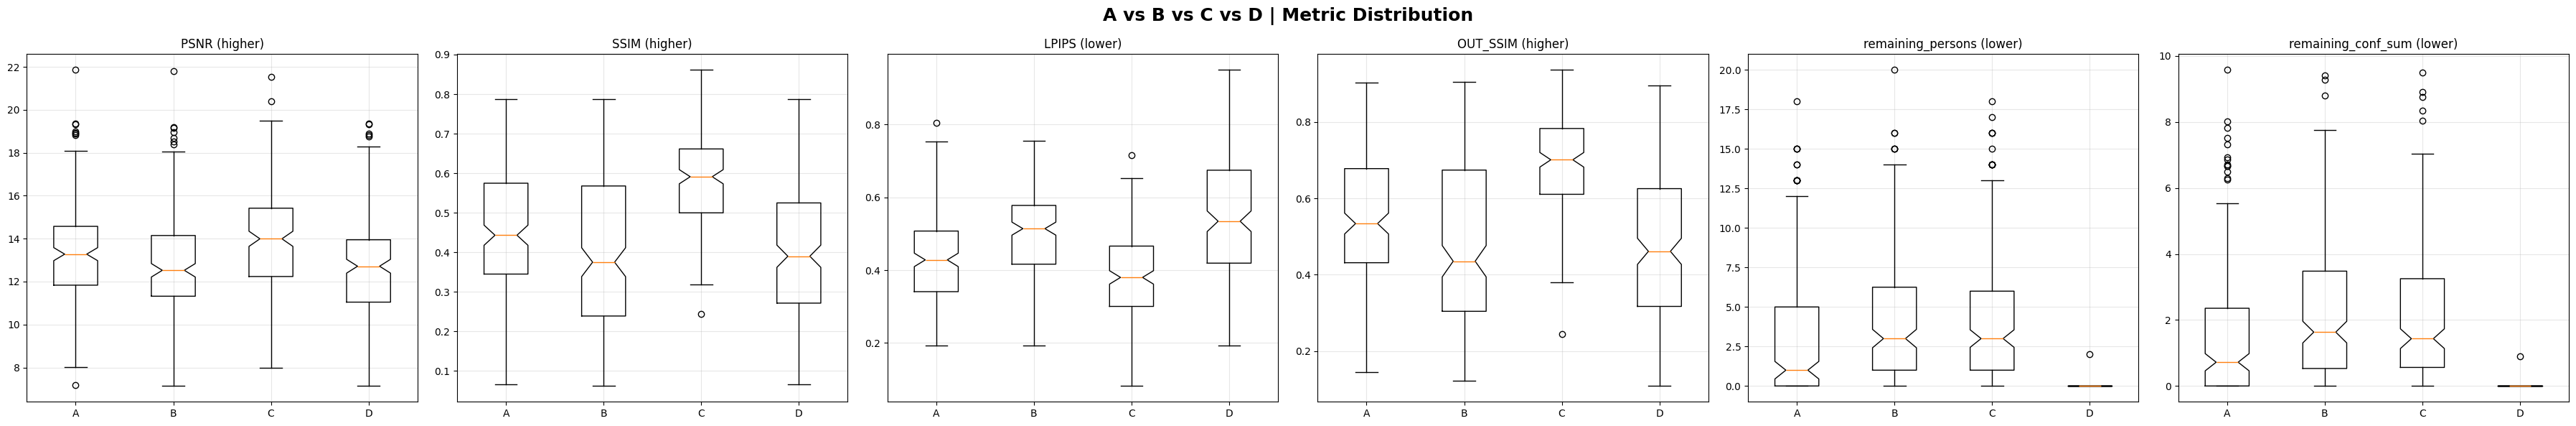

In [17]:
df = pd.read_csv(RESULTS_CSV)

fig, axes = plt.subplots(1, 6, figsize=(36, 6))
fig.suptitle("A vs B vs C vs D | Metric Distribution", fontsize=18, fontweight="bold")

metrics = [
    ("PSNR", "higher"),
    ("SSIM", "higher"),
    ("LPIPS", "lower"),
    ("OUT_SSIM", "higher"),
    ("remaining_persons", "lower"),
    ("remaining_conf_sum", "lower"),
]

for ax, (m, pref) in zip(axes, metrics):
    ax.boxplot([df[f"A_{m}"], df[f"B_{m}"], df[f"C_{m}"], df[f"D_{m}"]], labels=["A", "B", "C", "D"], notch=True)
    ax.set_title(f"{m} ({pref})")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_DIR / "boxplots_ABCD.png", dpi=180, bbox_inches="tight")
plt.show()


In [18]:
df = pd.read_csv(RESULTS_CSV)

df["improvement_score_D_vs_A"] = (
    1.5 * df["dPSNR_D_minus_A"]
    + 20.0 * df["dSSIM_D_minus_A"]
    - 12.0 * df["dLPIPS_D_minus_A"]
    + 12.0 * df["dOUT_SSIM_D_minus_A"]
    - 2.5 * df["dRemainPersons_D_minus_A"]
    - 1.2 * df["dRemainConf_D_minus_A"]
)

best_rows = df.sort_values("improvement_score_D_vs_A", ascending=False).head(NUM_VISUAL_SAMPLES_BEST)
worst_rows = df.sort_values("improvement_score_D_vs_A", ascending=True).head(NUM_VISUAL_SAMPLES_WORST)
rand_rows = df.sample(min(NUM_VISUAL_SAMPLES_RANDOM, len(df)), random_state=SEED)

selected_stems = set(best_rows["image"].tolist() + worst_rows["image"].tolist() + rand_rows["image"].tolist())
print("Selected visuals:", len(selected_stems))

for stem in tqdm(selected_stems):
    img_path = None
    for p in all_images:
        if Path(p).stem == stem:
            img_path = p
            break
    if img_path is None:
        continue

    image_rgb = read_rgb(img_path)
    persons = detect_and_segment(image_rgb)
    if len(persons) == 0:
        continue

    outA = method_A_single_shot_global(image_rgb, persons, best_cfg)
    outB = method_B_progressive_global(image_rgb, persons, best_cfg, sort_strategy="largest_first")
    outC = method_C_progressive_local(image_rgb, persons, best_cfg, sort_strategy="largest_first")
    outD = method_D_hybrid_global_then_refine(image_rgb, persons, best_cfg)

    mA = compute_all_metrics(image_rgb, outA["result"], outA["union_mask"])
    mB = compute_all_metrics(image_rgb, outB["result"], outB["union_mask"])
    mC = compute_all_metrics(image_rgb, outC["result"], outC["union_mask"])
    mD = compute_all_metrics(image_rgb, outD["result"], outD["union_mask"])

    save_path = VIS_DIR / f"{stem}_ABCD_compare.png"
    save_visual_grid(stem, image_rgb, persons, outA, outB, outC, outD, mA, mB, mC, mD, save_path)

print("Selected visuals saved to:", VIS_DIR)


Selected visuals: 27


  0%|          | 0/27 [00:00<?, ?it/s]

Selected visuals saved to: /content/cse498r_instance_removal_week_update/outputs/selected_visuals


Demo image: /content/cse498r_instance_removal_week_update/data/dataset_extracted/000000001000.jpg
Detected persons: 8


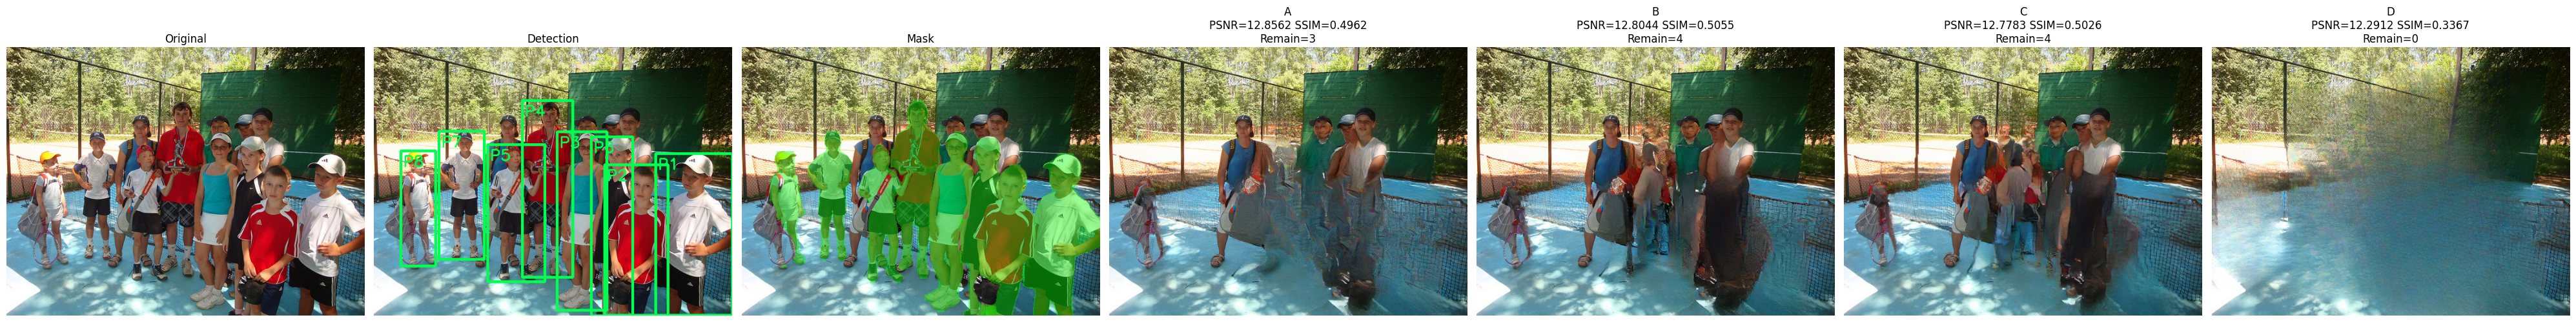

In [19]:
demo_path = str(all_images[0])

image_rgb = read_rgb(demo_path)
persons = detect_and_segment(image_rgb)

print("Demo image:", demo_path)
print("Detected persons:", len(persons))

if len(persons) == 0:
    plt.figure(figsize=(8, 6))
    plt.imshow(image_rgb)
    plt.title("No person detected")
    plt.axis("off")
    plt.show()
else:
    outA = method_A_single_shot_global(image_rgb, persons, best_cfg)
    outB = method_B_progressive_global(image_rgb, persons, best_cfg, sort_strategy="largest_first")
    outC = method_C_progressive_local(image_rgb, persons, best_cfg, sort_strategy="largest_first")
    outD = method_D_hybrid_global_then_refine(image_rgb, persons, best_cfg)

    mA = compute_all_metrics(image_rgb, outA["result"], outA["union_mask"])
    mB = compute_all_metrics(image_rgb, outB["result"], outB["union_mask"])
    mC = compute_all_metrics(image_rgb, outC["result"], outC["union_mask"])
    mD = compute_all_metrics(image_rgb, outD["result"], outD["union_mask"])

    rA = residual_person_score(outA["result"])
    rB = residual_person_score(outB["result"])
    rC = residual_person_score(outC["result"])
    rD = residual_person_score(outD["result"])

    det = overlay_detections(image_rgb, persons)
    seg = overlay_mask(image_rgb, persons)

    fig, axes = plt.subplots(1, 7, figsize=(40, 6))
    axes[0].imshow(image_rgb); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(det); axes[1].set_title("Detection"); axes[1].axis("off")
    axes[2].imshow(seg); axes[2].set_title("Mask"); axes[2].axis("off")
    axes[3].imshow(outA["result"]); axes[3].set_title(f"A\nPSNR={mA['PSNR']} SSIM={mA['SSIM']}\nRemain={rA['remaining_persons']}"); axes[3].axis("off")
    axes[4].imshow(outB["result"]); axes[4].set_title(f"B\nPSNR={mB['PSNR']} SSIM={mB['SSIM']}\nRemain={rB['remaining_persons']}"); axes[4].axis("off")
    axes[5].imshow(outC["result"]); axes[5].set_title(f"C\nPSNR={mC['PSNR']} SSIM={mC['SSIM']}\nRemain={rC['remaining_persons']}"); axes[5].axis("off")
    axes[6].imshow(outD["result"]); axes[6].set_title(f"D\nPSNR={mD['PSNR']} SSIM={mD['SSIM']}\nRemain={rD['remaining_persons']}"); axes[6].axis("off")
    plt.tight_layout()
    plt.show()


In [20]:
# Copy only important files
important_files = [
    RESULTS_CSV,
    SUMMARY_JSON,
]

if TUNE_CSV.exists():
    important_files.append(TUNE_CSV)

for f in important_files:
    if Path(f).exists():
        dst = DRIVE_OUT / Path(f).name
        shutil.copy2(f, dst)

# Copy plots
drive_plot_dir = DRIVE_OUT / "plots"
drive_plot_dir.mkdir(parents=True, exist_ok=True)
for f in PLOT_DIR.glob("*"):
    if f.is_file():
        shutil.copy2(f, drive_plot_dir / f.name)

# Copy selected visuals only
drive_vis_dir = DRIVE_OUT / "selected_visuals"
drive_vis_dir.mkdir(parents=True, exist_ok=True)
for f in VIS_DIR.glob("*"):
    if f.is_file():
        shutil.copy2(f, drive_vis_dir / f.name)

print("Copied important outputs to Drive.")
print("Drive folder:", DRIVE_OUT)


Copied important outputs to Drive.
Drive folder: /content/drive/MyDrive/cse498r_instance_removal_week_update/outputs


In [22]:
FINAL_ZIP = DRIVE_OUT / "final_outputs_ABCD.zip"

with zipfile.ZipFile(FINAL_ZIP, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in important_files:
        f = Path(f)
        if f.exists():
            zf.write(f, arcname=f.name)

    for f in PLOT_DIR.glob("*"):
        if f.is_file():
            zf.write(f, arcname=f"plots/{f.name}")

    for f in VIS_DIR.glob("*"):
        if f.is_file():
            zf.write(f, arcname=f"selected_visuals/{f.name}")

print("Final zip saved to:", FINAL_ZIP)


Final zip saved to: /content/drive/MyDrive/cse498r_instance_removal_week_update/outputs/final_outputs_ABCD.zip


# CSE 498R Weekly Progress Update  
## Adaptive and Hybrid Strategies for Multi-Person Instance Removal

## 1. Objective of This Week

The main goal of this week was to go beyond the previous baseline comparison and produce a **more meaningful and research-oriented evaluation** for the person instance removal task.

Last week, the comparison mainly focused on two strategies:

- **Method A: Single-shot global removal**
- **Method B: Progressive global removal**

That earlier comparison suggested that the progressive strategy could perform well under image-based metrics such as PSNR, SSIM, and LPIPS. However, after further analysis, it became clear that those metrics alone were **not sufficient** for evaluating an object removal pipeline. A method may obtain good image similarity scores while still leaving behind visible or detectable person regions.

Therefore, the target of this week was twofold:

1. **Improve the removal pipeline itself**
2. **Strengthen the evaluation so the results become more scientifically meaningful**

The broader research goal is to develop a pipeline that can remove multiple people from an image while maintaining natural image quality, preserving the background, and minimizing residual person detections.

---

## 2. What Was Done Previously

In the previous phase of the work, the system used:

- **YOLO segmentation** to detect persons and obtain masks
- **Simple LaMa inpainting** to fill the removed regions
- Two removal strategies:
  - **A: Single-shot** — remove all detected persons using one combined mask
  - **B: Progressive** — remove persons one by one

The previous evaluation used:

- **PSNR**
- **SSIM**
- **LPIPS**

These metrics were calculated between the original image and the edited output inside the edited region.

Although this gave useful information, it had an important limitation:

> The original image contains the people, while the final edited image is supposed to remove them.  
> So comparing the edited image directly to the original image does not fully represent true removal quality.

This motivated a stronger evaluation and new method development this week.

---

## 3. Main Problems Identified

During analysis, the following issues were identified:

### 3.1 Evaluation limitation
The earlier evaluation could indicate whether an edited image remained visually close to the original, but it could not tell whether the method had actually removed the persons successfully.

### 3.2 Fixed mask engineering
The earlier pipeline used mostly fixed mask processing settings for all images. But the dataset contains images with:

- different resolutions
- different numbers of persons
- different person sizes
- crowded and non-crowded scenes

A single fixed mask-processing strategy is not ideal across all such cases.

### 3.3 Trade-off between removal and quality
More aggressive inpainting can reduce residual persons, but may also damage the background and reduce visual quality. Less aggressive inpainting preserves more structure, but may fail to fully remove all persons.

This week’s work focused on addressing these issues.

---

## 4. Dataset and Experimental Setup

The experiments were run on a **200-image COCO-based multi-person dataset** prepared earlier.

Each image contains at least one detected person, and the dataset includes scenes with varying crowd sizes, viewpoints, and object/person overlap.

The pipeline was implemented in **Google Colab** using GPU acceleration.

### Core components
- **YOLOv8 segmentation model** for person detection and mask extraction
- **Simple LaMa** for inpainting
- **LPIPS** for perceptual similarity
- **PSNR and SSIM** for proxy image-consistency measurement

---

## 5. Methods Investigated This Week

This week the study was extended from two methods to four:

---

### Method A — Single-shot Global Inpainting
All detected person masks are merged into one union mask, and the image is inpainted in a single step.

#### Intended advantage
- Simple and fast
- Removes all target persons in one pass

#### Limitation
- Large removed region may reduce fine local quality
- May create artifacts in crowded scenes

---

### Method B — Progressive Global Inpainting
Persons are removed one by one globally, usually ordered by size.

#### Intended advantage
- Allows gradual editing
- May handle overlapping persons better than one-shot global removal

#### Limitation
- Can accumulate errors over multiple inpainting passes
- Often slower than A

---

### Method C — Progressive Local Inpainting
Each detected person is removed using an adaptive local crop and local inpainting strategy, rather than applying full-image inpainting for each step.

#### Main design idea
- Use **adaptive mask dilation and blur**
- Use **local crop inpainting**
- Blend the result back into the image

#### Intended advantage
- Better local detail preservation
- Better visual quality and background consistency

#### Limitation
- May still leave residual detectable person structures
- Local refinement alone may not guarantee full removal

---

### Method D — Hybrid Global-Then-Refine Strategy
This was introduced as a stronger refinement-based method.

#### Stage 1
Apply **global single-shot removal** using the union mask, similar to Method A.

#### Stage 2
Run person detection again on the edited output. If any residual persons are still detected, apply **targeted refinement passes** only on those leftover detected regions.

#### Intended advantage
- Combines strong global removal with targeted cleanup
- Specifically designed to minimize residual detectable persons

#### Limitation
- Can become visually aggressive
- May over-smooth or over-remove surrounding content
- May reduce visual realism

---

## 6. Evaluation Improvements Introduced This Week

One of the most important parts of this week’s work was improving the evaluation protocol.

Previously, only image similarity metrics were used. This week, the evaluation was expanded to include metrics that better reflect actual removal behavior.

### 6.1 Inside-mask proxy metrics
These are still used as quality indicators inside the edited region:

- **PSNR** — higher is better
- **SSIM** — higher is better
- **LPIPS** — lower is better

These are treated as **proxy visual-consistency metrics**, not absolute ground-truth reconstruction metrics.

---

### 6.2 Outside-mask preservation metric
A new metric was added:

- **OUT_SSIM** — higher is better

This measures how well the image structure outside the main edited region is preserved. This is important because a method should not unnecessarily damage the background while removing people.

---

### 6.3 Residual detection-based removal metrics
These are the strongest additions this week:

- **RemainPersons** — number of persons still detected after removal
- **RemainConf** — total confidence of remaining detected persons

These metrics directly evaluate whether the system has actually suppressed the person instances.

This addition changed the interpretation of the experiments significantly.

---

## 7. What the Notebook Pipeline Now Does

The updated notebook now performs the following steps:

1. Load the dataset
2. Detect and segment persons using YOLO
3. Generate masks
4. Apply one of the removal methods (A, B, C, or D)
5. Compute:
   - inside-mask PSNR / SSIM / LPIPS
   - outside-mask SSIM
   - residual person detection count and confidence
   - runtime
6. Save:
   - CSV results
   - summary JSON
   - plots
   - selected visual comparisons
   - final zip archive

This makes the workflow more complete and more suitable for research reporting.

---

## 8. Summary of Results Obtained

The final averaged results were:

| Method | PSNR ↑ | SSIM ↑ | LPIPS ↓ | OUT_SSIM ↑ | RemainPersons ↓ | RemainConf ↓ | Time(s) ↓ |
|--------|-------:|-------:|--------:|-----------:|----------------:|-------------:|----------:|
| A Single-shot | 13.3552 | 0.4526 | 0.4340 | 0.5455 | 3.13 | 1.5637 | 0.1672 |
| B Progressive-global | 12.7937 | 0.3974 | 0.4919 | 0.4765 | 4.385 | 2.2815 | 1.0473 |
| C Progressive-local | **13.9627** | **0.5830** | **0.3872** | **0.6868** | 4.125 | 2.1481 | 0.3823 |
| D Hybrid-refine | 12.7361 | 0.3985 | 0.5462 | 0.4751 | **0.01** | **0.0044** | 0.9578 |

---

## 9. Interpretation of the Results

### 9.1 Method C is best in visual quality
Method C achieved the best results on:

- **PSNR**
- **SSIM**
- **LPIPS**
- **OUT_SSIM**

This means Method C produces the most visually consistent and perceptually pleasing outputs among all tested methods. It also preserves the surrounding background structure better than the others.

This is a strong improvement over the earlier global progressive approach.

---

### 9.2 Method D is best in removal completeness
Method D achieved the best results on:

- **RemainPersons**
- **RemainConf**

Its values are almost zero, which means it is highly effective at removing detectable person instances.

This is a major improvement in actual object-removal behavior.

---

### 9.3 Method B is no longer competitive
Compared to the other methods, Method B performed poorly in both visual quality and residual detection.

This suggests that the older progressive-global strategy is not the best direction moving forward.

---

### 9.4 Method A remains a strong baseline
Method A still provides a good balance:
- fast runtime
- acceptable visual quality
- moderate removal ability

It remains a strong baseline for comparison.

---

## 10. Key Research Insight Obtained This Week

The most important finding from this week is:

> There is a clear trade-off between **visual realism** and **removal completeness**.

### Method C
- best visual quality
- best background preservation
- but still leaves too many detectable persons

### Method D
- best actual removal completeness
- but damages visual quality significantly

This trade-off was not visible in the previous week because the evaluation was not strong enough to expose it.

That means this week’s work did not just improve implementation — it improved understanding of the problem itself.

---

## 11. Comparison with Previous Week

Compared to last week, this week’s work is better in several important ways.

### 11.1 More methods were explored
The method set expanded from A/B to A/B/C/D.

### 11.2 Evaluation became much stronger
Last week relied mainly on PSNR/SSIM/LPIPS.  
This week added:

- OUT_SSIM
- RemainPersons
- RemainConf

These new metrics make the evaluation much more realistic for an instance removal problem.

### 11.3 A stronger research conclusion was reached
Last week only suggested which method looked better numerically under image-similarity metrics.  
This week showed that:
- a method can look visually better but remove worse
- another method can remove better but look visually worse

This is a more meaningful and publishable type of insight.

---

## 12. What We Achieved This Week

This week achieved the following concrete progress:

- built a more advanced multi-method comparison framework
- added adaptive local inpainting strategy
- added hybrid residual-refinement strategy
- added stronger evaluation metrics
- completed full 200-image evaluation successfully
- generated plots and qualitative visual results
- identified the central quality-vs-removal trade-off

These are strong signs of real progress, even though the final best unified method has not yet been reached.

---

## 13. What Still Needs Improvement

Although the progress is substantial, the work is not complete yet.

### Current limitation
There is no single method that is best in all metrics:

- **C** is best for visual quality
- **D** is best for complete removal

### What is missing
The next target is to design a method that:
- keeps D’s strong person suppression
- while preserving the visual realism and structure quality of C

That is the main unresolved challenge.

---

## 14. Planned Next Direction

The next phase should focus on improving Method D so that it becomes less destructive.

Possible directions include:

- reduce aggressiveness of residual refinement
- refine only high-confidence residual detections
- use smaller refinement masks
- reduce the number of refinement passes
- apply softer local blending after refinement
- combine C and D adaptively depending on scene complexity

The ideal goal is a new method that provides:

- low residual detections like D
- high visual quality like C

---

## 15. Final Conclusion

This week’s work significantly improved the project in both implementation and evaluation.

The major contributions of the week are:

1. **Extending the method set** from simple baselines to adaptive and hybrid strategies
2. **Introducing stronger evaluation**, especially detector-based removal metrics
3. **Revealing the core trade-off** between visual quality and true removal completeness

The final conclusion is:

- **Method C** is currently the strongest option for visual quality and background preservation
- **Method D** is currently the strongest option for complete person removal
- the next challenge is to combine these strengths into one more balanced method

Overall, this week’s results represent a meaningful step toward a stronger and more research-worthy instance removal system.
